# Analisis Segmentasi Negara dan Pembangunan Ekonomi
---

## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar Belakang**: Sebuah lembaga bantuan internasional dan analis kebijakan global ingin membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan status sosio-ekonomi dan kesehatan dari berbagai negara di seluruh dunia secara otomatis ke dalam beberapa klaster kelompok pembangunan.
2.**Masalah**:Lembaga tersebut masih melakukan pengelompokan pembangunan secara manual satu per satu yang memakan banyak waktu.
3. **Solusi**: Membuat model *machine learning* dengan algoritma **K-Means++** untuk mengelompokkan status sosio-ekonomi dan kesehatan secara otomatis.

### 1.2 Deskripsi dataset `Country_data`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `country` | `str` | Nama negara (string / teks). |
| `child_mort` | `float64` | Angka kematian anak di bawah usia 5 tahun per 1.000 kelahiran hidup. |
| `exports` | `float64` | Persentase ekspor barang dan jasa terhadap PDB (GDP). |
| `health` | `float64` | Persentase pengeluaran total kesehatan terhadap PDB (GDP). |
| `imports` | `float64` | Persentase impor barang dan jasa terhadap PDB (GDP). |
| `income` | `int64` | Pendapatan bersih per kapita (satuan: USD). |
| `inflation` | `float64` | Tingkat pertumbuhan tahunan total inflasi dari PDB. |
| `life_expec` | `float64` | Rata-rata angka harapan hidup saat lahir (satuan: Tahun). |
| `total_fer` | `float64` | Angka kesuburan total / rata-rata jumlah anak yang dilahirkan oleh seorang wanita. |
| `gdpp` | `int64` | Produk Domestik Bruto per kapita (satuan: USD per orang). |

---
## 2. Data Preparation

### 2.1 Import library

In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [25]:
df = pd.read_csv('Country-data.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampilkan data teratas dan data terbawah

In [26]:
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [27]:
df.tail()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310
166,Zambia,83.1,37.0,5.89,30.9,3280,14.00,52.0,5.40,1460


### 2.4 Tampilkan informasi data

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [29]:
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'---- missing value setiap kolom ---- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\njumlha data duplikat: {df.duplicated().sum()}')

Jumlah data: 1670

Jumlah missing value: 0
---- missing value setiap kolom ---- 
Series([], dtype: int64)

jumlha data duplikat: 0


---
## 3.Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [30]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


### 3.2 Memeriksa outlier dengan IQR dan Z-Score

In [31]:
outliers = []
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        skew = df[col].skew()
        min_val = df[col].min()
        max_val = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'kemiringan': skew,
            'min': min_val,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max_val,
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,kemiringan,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,child_mort,38.270060,40.328931,1.450774,2.6000,8.250,19.30,62.10,208.00,-72.5250,142.8750,4,2
1,exports,41.108976,27.412010,2.445824,0.1090,23.800,35.00,51.35,200.00,-17.5250,92.6750,5,3
2,health,6.815689,2.746837,0.705746,1.8100,4.920,6.32,8.60,17.90,-0.6000,14.1200,2,1
3,imports,46.890215,24.209589,1.905276,0.0659,30.200,43.30,58.75,174.00,-12.6250,101.5750,4,3
4,income,17144.688623,19278.067698,2.231480,609.0000,3355.000,9960.00,22800.00,125000.00,-25812.5000,51967.5000,8,4
5,inflation,7.781832,10.570704,5.154049,-4.2100,1.810,5.39,10.75,104.00,-11.6000,24.1600,5,2
6,life_expec,70.555689,8.893172,-0.970996,32.1000,65.300,73.10,76.80,82.80,48.0500,94.0500,3,1
7,total_fer,2.947964,1.513848,0.967092,1.1500,1.795,2.41,3.88,7.49,-1.3325,7.0075,1,1
8,gdpp,12964.155689,18328.704809,2.218051,231.0000,1330.000,4660.00,14050.00,105000.00,-17750.0000,33130.0000,25,4


### 3.3 Visualisasi outlier dengan boxplot

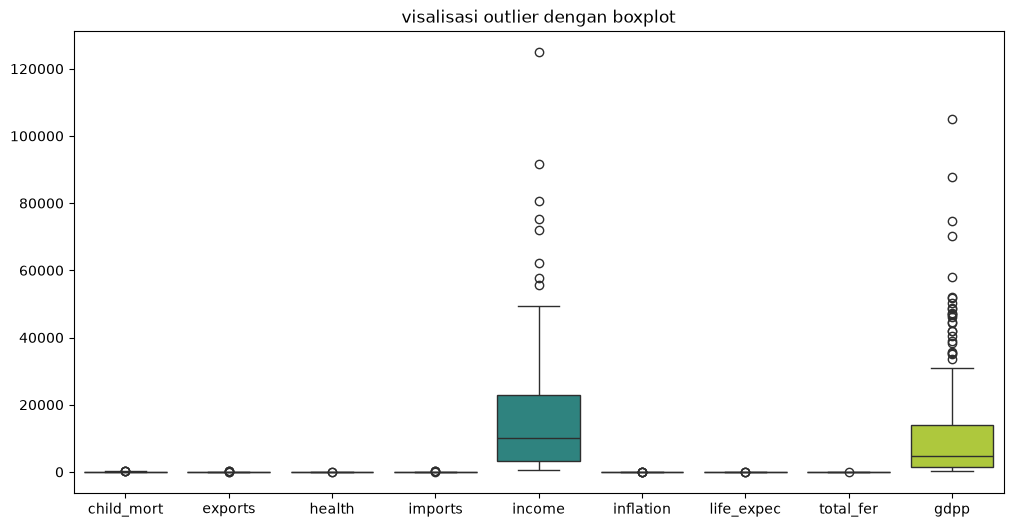

In [32]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, palette='viridis')
plt.title('visalisasi outlier dengan boxplot')
plt.show()

**insight**: Grafik boxplot menunjukan adanya titik titik oulier pada keseluruhan kolom dan terdapat ketimpangan skala yang ekstrem antara fitur `income` dan `gdpp`. oleh karena itu, keputusan sementara pada tahap data preprocessing yaitu dengan membatasi nilai outlier menggunakan metode capping IQR tanpa menghapus baris data dan menyamakan rentan keseluruhan variabel memalui feature scalling.

### 3.4 Visualisasi distribusi data numerik

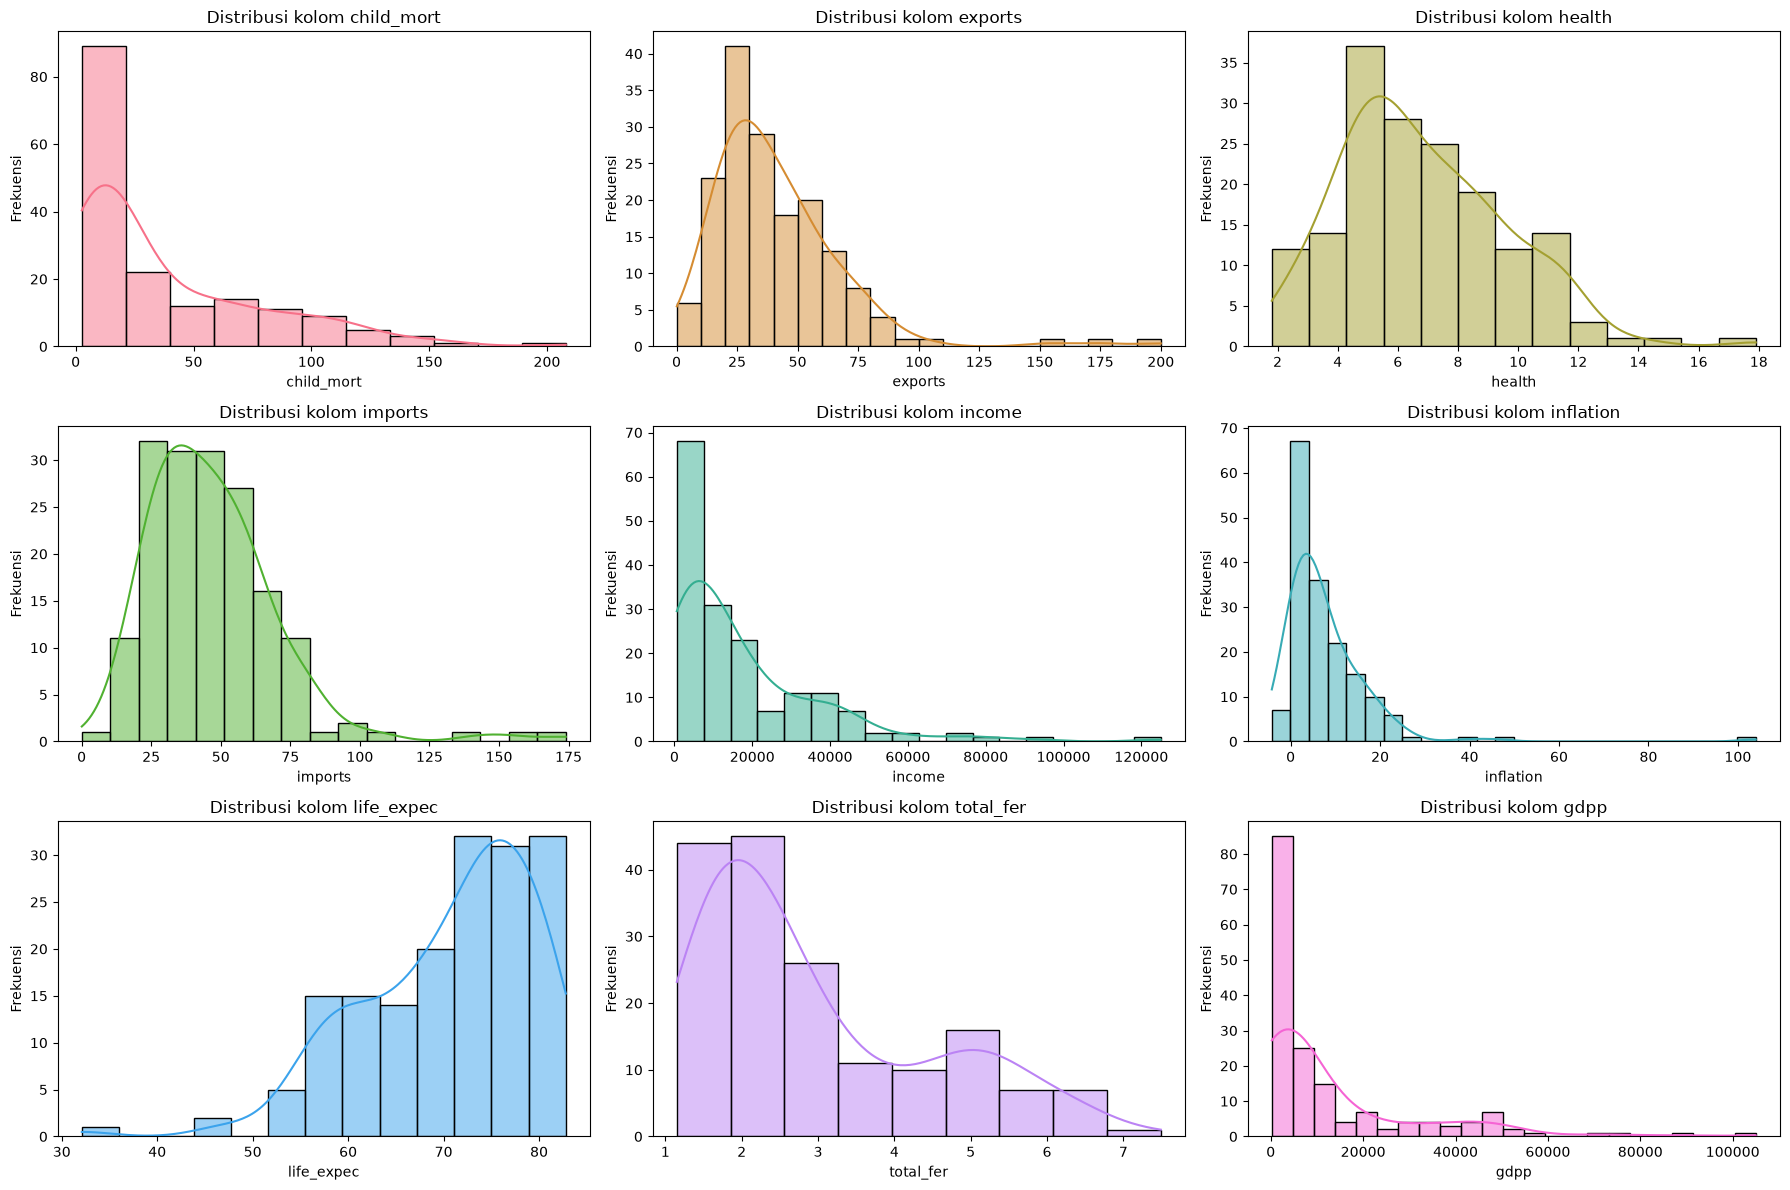

In [33]:
numeric = df.select_dtypes(include=[np.number]).columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(numeric) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

colors = sns.color_palette('husl', len(numeric))

for i, col in enumerate(numeric):
    sns.histplot(data=df, x=col, kde=True, color=colors[i], ax=axes[i])
    axes[i].set_title(f'Distribusi kolom {col}')
    axes[i].set_ylabel('Frekuensi')
    
for j in range(len(numeric), len(axes)):
    axes[j].set_visible(False)
    
plt.tight_layout()
plt.show()

**insight**: grafik distribusi data menunjukkan bahwa keseluruhan fitur numerik bersifat miring (*skewed*) dan tidak berdistribusi normal.

### 3.5 Analisis korelasi pada kolom numerik

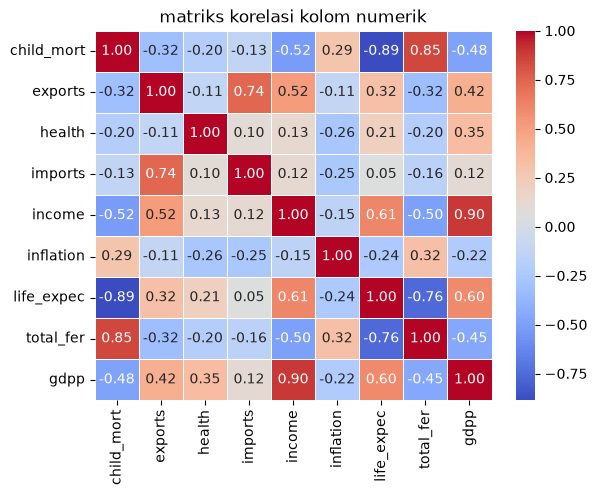

In [34]:
numeric = ['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']
korelasi = df[numeric].corr(method='pearson')
sns.heatmap(korelasi, cmap='coolwarm', annot=True, fmt=".2f", linewidths=0.5)
plt.title('matriks korelasi kolom numerik')
plt.show()

**Insight**: Mtriks korelasi tersebut menunjukkan adanya korelasi yang kuat pada beberapa kolom, seperti kolom `gdpp` dan `income` (0.90) serta `child_mort` dan `total_fer` (0.85), sedangkan korelasi negatif yang kuat terliaht antara `life_expe` dan `child_mort`(-0.89).

### 3.6 eksplorasi pola sebaran pasangan fitur berkorelasi tinggi

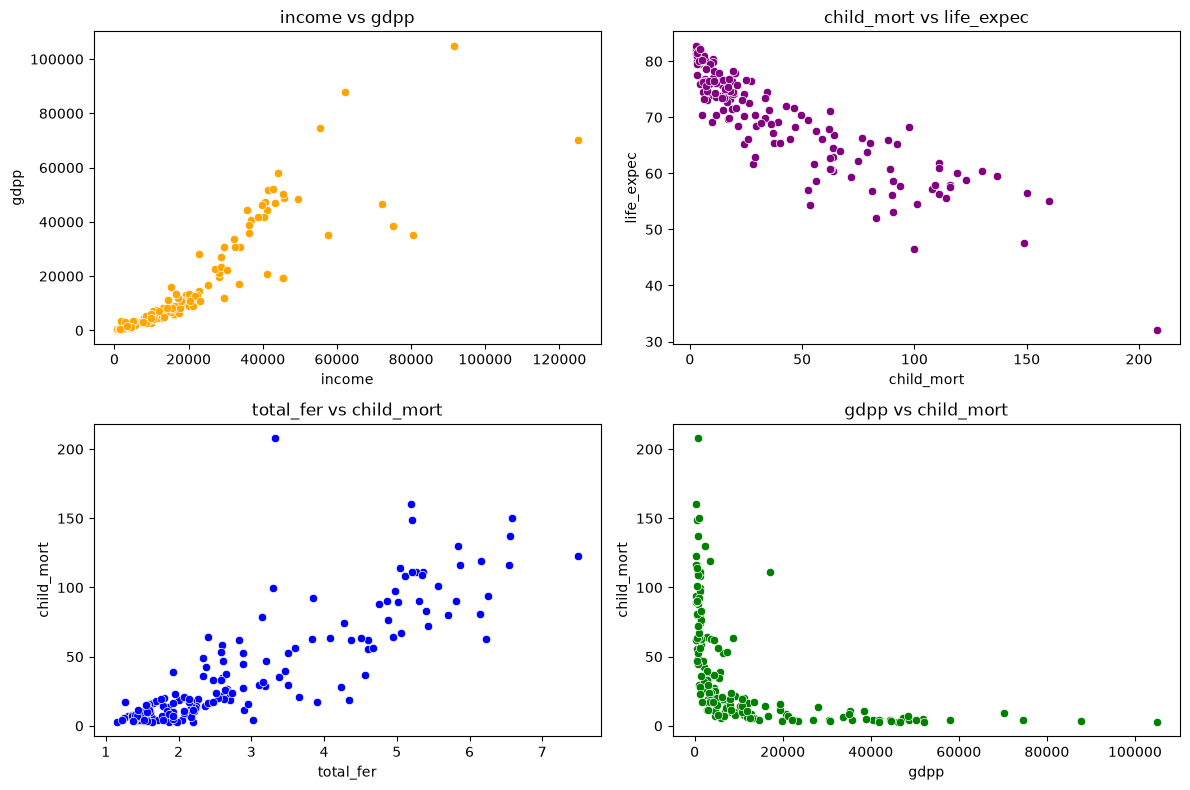

In [35]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

ax1 = axes[0,0]
sns.scatterplot(data=df, x='income', y='gdpp', color='orange', ax=axes[0,0])
ax1.set_title('income vs gdpp')

ax1 = axes[0,1]
sns.scatterplot(data=df, x='child_mort', y='life_expec', color='purple', ax=axes[0,1])
ax1.set_title('child_mort vs life_expec')

ax1 = axes[1,0]
sns.scatterplot(data=df, x='total_fer', y='child_mort', color='blue', ax=axes[1,0])
ax1.set_title('total_fer vs child_mort')

ax1 = axes[1,1]
sns.scatterplot(data=df, x='gdpp', y='child_mort', color='green', ax=axes[1,1])
ax1.set_title('gdpp vs child_mort')

plt.tight_layout()
plt.show()

**Insight**:Visualisasi scatter plot menunjukkan bahwa income dan gdpp berbanding lurus satu sama lain serta berbanding terbalik dengan tingkat kematian anak (child_mort) dan tingkat kelahiran (total_fer). Pola sebaran berbentuk huruf L pada hubungan gdpp dan child_mort memperlihatkan pemisahan antara negara tertinggal, negara berkembang, dan negara maju.

---
## 4. Data Preprocessing

### 4.1 Penangan outlier dengan capping

Penggunaan metode capping berbasis batas IQR diterapkan dibandingkan penghapusan data maupun metode lainnya karena nilai ekstrem pada dataset ini merepresentasikan kondisi nyata negara maju dan negara tertinggal yang harus dipertahankan agar seluruh 167 negara tetap utuh tanpa menarik posisi centroid secara berlebihan.

In [36]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    df[col] = np.clip(df[col], lower, upper)
    m = df[(df[col] < lower) | (df[col] > upper)]
    print(f'jumlah outlier pada kolom {df[col]} setelah capping: {m.shape[0]}')

print("Jumlah baris setelah capping:", len(df))

jumlah outlier pada kolom 0       90.2
1       16.6
2       27.3
3      119.0
4       10.3
       ...  
162     29.2
163     17.1
164     23.3
165     56.3
166     83.1
Name: child_mort, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      10.0
1      28.0
2      38.4
3      62.3
4      45.5
       ... 
162    46.6
163    28.5
164    72.0
165    30.0
166    37.0
Name: exports, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      7.58
1      6.55
2      4.17
3      2.85
4      6.03
       ... 
162    5.25
163    4.91
164    6.84
165    5.18
166    5.89
Name: health, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0      44.9
1      48.6
2      31.4
3      42.9
4      58.9
       ... 
162    52.7
163    17.6
164    80.2
165    34.4
166    30.9
Name: imports, Length: 167, dtype: float64 setelah capping: 0
jumlah outlier pada kolom 0       1610.0
1       9930.0
2      12900.0
3       5900.0
4      19100.0
      

### 4.2 Visualisasi grafik boxplot setelah capping outlier

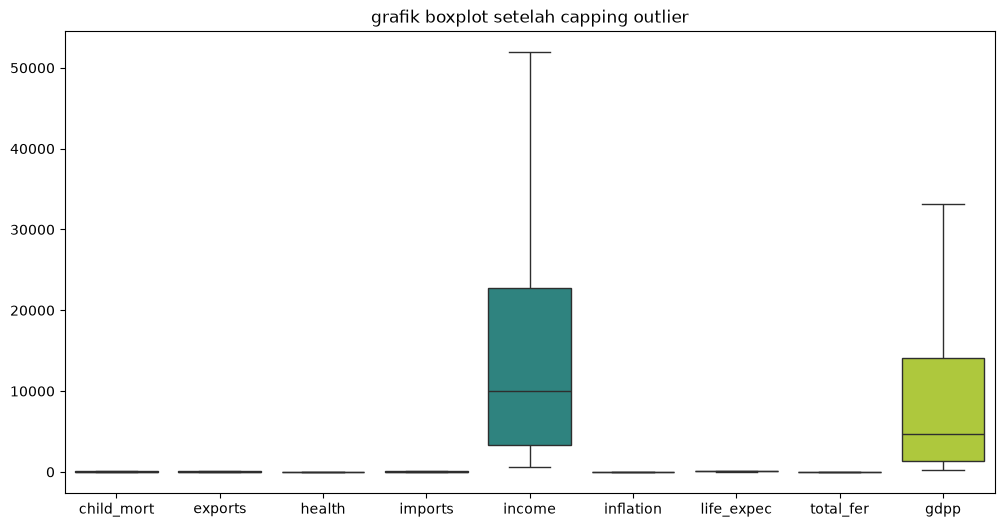

In [37]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, palette='viridis')
plt.title('grafik boxplot setelah capping outlier')
plt.show()

**Insight**: gafik menunjukan keseluruhan kolom telah bebas dari outlier dengan ditandai titik titik outlier yang menghilang seetalah capping.

### 4.3. Scalling kolom numerik dengan MinMaxScalling

Penggunaan metode MinMaxScaling diterapkan setelah proses capping IQR karena mampu menyetarakan seluruh variabel ke dalam rentang seragam 0 hingga 1 tanpa terdistorsi nilai ekstrem, sehingga fitur berskala besar seperti `income` dan `gdpp` tidak lagi mendominasi perhitungan jarak Euclidean pada tahap modeling.

In [38]:
X = df[numeric_cols].to_numpy(dtype=float)

X_scaled = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))

df_scaled = pd.DataFrame(X_scaled, columns=numeric_cols)

df_scaled.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,0.250210,0.426016,0.404758,0.451153,0.298151,0.397429,0.650756,0.306458,0.307617
std,0.274057,0.230120,0.216743,0.200364,0.296099,0.236340,0.245253,0.257032,0.352960
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.040278,0.255936,0.252640,0.296861,0.053467,0.212196,0.496403,0.110115,0.033405
50%,0.119052,0.376931,0.366369,0.425914,0.182073,0.338386,0.720863,0.215109,0.134624
75%,0.424167,0.553562,0.551584,0.578117,0.432080,0.527318,0.827338,0.466069,0.420043
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### 4.4 visualisasi setelah scalling

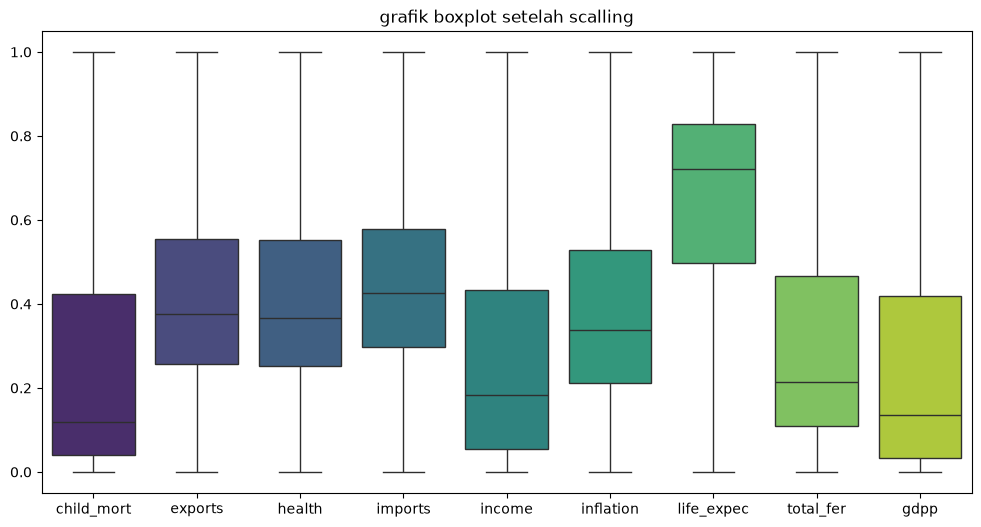

In [39]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_scaled, palette='viridis', whis=(0, 100))
plt.title('grafik boxplot setelah scalling')
plt.show()

**Insight**: Grafik boxplot setelah penyekalaan menunjukkan bahwa seluruh sembilan fitur numerik kini memiliki rentang nilai yang seragam pada skala 0,0 hingga 1,0 tanpa ada lagi titik outlier maupun variabel yang mendominasi tampilan grafik.

---

## 5. Modelling

### 5.1 Membangun Algoritma K-Means++ Clustering

In [40]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

class KMeansPlusPlus:
    def __init__(self, K=3, max_iters=100, random_state=43):
        self.K = K
        self.max_iters = max_iters
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = []

    def _init_centroids(self):
        np.random.seed(self.random_state)
        centroids = [self.X[np.random.randint(self.n_samples)]]

        for _ in range(1, self.K):
            dist_sq = np.array([min([np.sum((x - c) ** 2) for c in centroids]) for x in self.X])
            probs = dist_sq / np.sum(dist_sq)
            idx = np.random.choice(self.n_samples, p=probs)
            centroids.append(self.X[idx])

        return np.array(centroids)

    def predict(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape
        self.centroids = self._init_centroids()

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)
            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self._is_converged(centroids_old, self.centroids):
                break

        return self._get_cluster_labels(self.clusters)

    def _create_clusters(self, centroids):
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(sample, centroids)
            clusters[centroid_idx].append(idx)
        return clusters

    def _closest_centroid(self, sample, centroids):
        distances = [euclidean_distance(sample, point) for point in centroids]
        return np.argmin(distances)

    def _get_centroids(self, clusters):
        centroids = np.zeros((self.K, self.n_features))
        for cluster_idx, cluster in enumerate(clusters):
            centroids[cluster_idx] = np.mean(self.X[cluster], axis=0)
        return centroids

    def _is_converged(self, centroids_old, centroids):
        distances = [euclidean_distance(centroids_old[i], centroids[i]) for i in range(self.K)]
        return sum(distances) == 0
    
    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples, dtype=int)
        for cluster_idx, cluster in enumerate(clusters):
            for sample_idx in cluster:
                labels[sample_idx] = cluster_idx
        return labels

### 5.2 Menyiapkan Matrik Fitur dan Melatih Model

In [41]:
model_kmeans = KMeansPlusPlus(K=3, max_iters=100, random_state=43)
cluster_labels = model_kmeans.predict(X_scaled)

print("Ukuran data input:", X_scaled.shape)
print("Ukuran centroid akhir:", model_kmeans.centroids.shape)
print("10 label cluster pertama:", cluster_labels[:10])

Ukuran data input: (167, 9)
Ukuran centroid akhir: (3, 9)
10 label cluster pertama: [1 2 2 1 2 2 2 0 0 2]


### 5.3 Menggabungkan Label Cluster

In [42]:
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

print("Jumlah negara tiap cluster:")
print(df_clustered['Cluster'].value_counts().sort_index())

Jumlah negara tiap cluster:
Cluster
0    39
1    48
2    80
Name: count, dtype: int64


---

## 6. Evaluation

### 6.1 Menghitung Metrik Evaluasi Model (WCSS / SSE dan Silhouette Score)

In [43]:
def hitung_wcss(X, labels, centroids):
    wcss = 0
    for i in range(len(centroids)):
        poin_cluster = X[labels == i]
        wcss += np.sum((poin_cluster - centroids[i]) ** 2)
    return wcss

def hitung_silhouette_score(X, labels):
    n = len(X)
    jarak = np.sqrt(np.sum((X[:, None] - X[None, :]) ** 2, axis=2))
    skor = []

    for i in range(n):
        klaster_sendiri = labels == labels[i]
        klaster_sendiri[i] = False
        a_i = np.mean(jarak[i, klaster_sendiri])

        b_i = min([
            np.mean(jarak[i, labels == k])
            for k in set(labels) if k != labels[i]
        ])

        skor.append((b_i - a_i) / max(a_i, b_i))

    return np.mean(skor)

wcss_utama = hitung_wcss(X_scaled, cluster_labels, model_kmeans.centroids)
silhouette_utama = hitung_silhouette_score(X_scaled, cluster_labels)

print(f"Hasil Evaluasi Model (K = {model_kmeans.K}):")
print(f"WCSS / SSE       : {wcss_utama:.4f}")
print(f"Silhouette Score : {silhouette_utama:.4f}")

Hasil Evaluasi Model (K = 3):
WCSS / SSE       : 42.1252
Silhouette Score : 0.3369


### 6.2 Evaluasi Perbandingan Jumlah Cluster (K = 1 - 10)

Tabel Perbandingan Evaluasi Nilai K:
   Jumlah Cluster (K)  WCSS / SSE  Silhouette Score
0                   2     60.5533            0.3582
1                   3     42.1252            0.3369
2                   4     37.6381            0.2841
3                   5     36.2340            0.2455
4                   6     33.2391            0.1956
5                   7     29.6502            0.2162
6                   8     27.5042            0.2163
7                   9     25.6210            0.2213


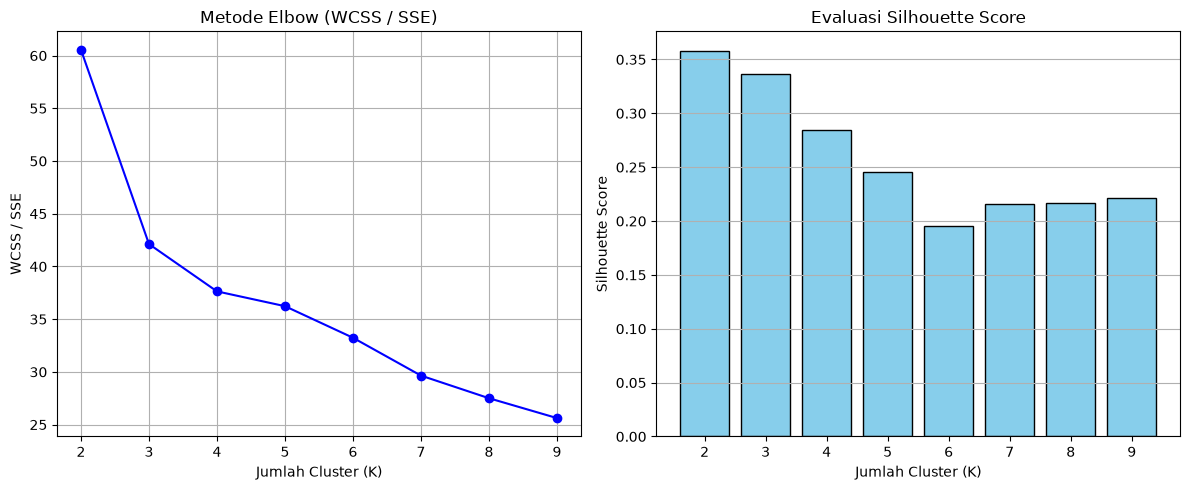

In [44]:
hasil_evaluasi = []

for k in range(2, 10):
    model_uji = KMeansPlusPlus(K=k, max_iters=100, random_state=43)
    label_uji = model_uji.predict(X_scaled)

    wcss = hitung_wcss(X_scaled, label_uji, model_uji.centroids)
    sil = hitung_silhouette_score(X_scaled, label_uji)

    hasil_evaluasi.append({
        'Jumlah Cluster (K)': k,
        'WCSS / SSE': round(wcss, 4),
        'Silhouette Score': round(sil, 4)
    })

df_evaluasi_k = pd.DataFrame(hasil_evaluasi)
print("Tabel Perbandingan Evaluasi Nilai K:")
print(df_evaluasi_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(df_evaluasi_k['Jumlah Cluster (K)'], df_evaluasi_k['WCSS / SSE'], marker='o', color='blue')
axes[0].set_title('Metode Elbow (WCSS / SSE)')
axes[0].set_xlabel('Jumlah Cluster (K)')
axes[0].set_ylabel('WCSS / SSE')
axes[0].grid(True)

axes[1].bar(df_evaluasi_k['Jumlah Cluster (K)'], df_evaluasi_k['Silhouette Score'], color='skyblue', edgecolor='black')
axes[1].set_title('Evaluasi Silhouette Score')
axes[1].set_xlabel('Jumlah Cluster (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()

### 6.3 Evaluasi Profil Karakteristik Cluster & Pemetaan Kategori Pembangunan Negara

Pemetaan Cluster:
Cluster 1 -> Rendah
Cluster 2 -> Menengah
Cluster 0 -> Tinggi


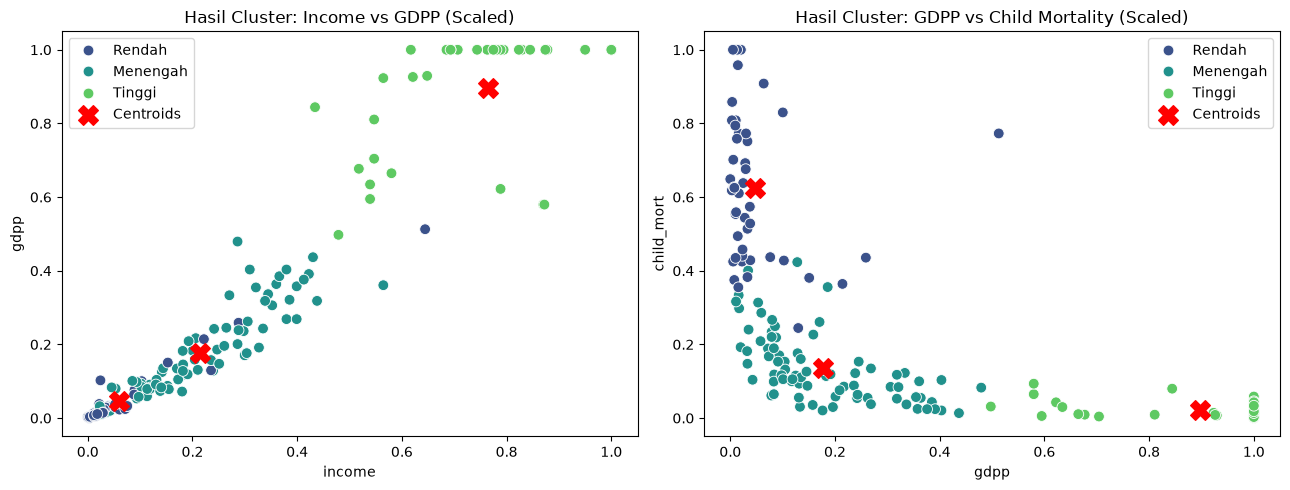

In [45]:
urutan_gdpp = df_clustered.groupby('Cluster')['gdpp'].mean().sort_values().index
kategori = ["Rendah", "Menengah", "Tinggi"]

cluster_label_map = {klaster: kategori[i] for i, klaster in enumerate(urutan_gdpp)}
df_clustered['Kategori_Pembangunan'] = df_clustered['Cluster'].map(cluster_label_map)

print("Pemetaan Cluster:")
for cid, nama in cluster_label_map.items():
    print(f"Cluster {cid} -> {nama}")

df_plot = df_scaled.copy()
df_plot['Kategori_Pembangunan'] = df_clustered['Kategori_Pembangunan']
centroids_df = pd.DataFrame(model_kmeans.centroids, columns=numeric_cols)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df_plot, x='income', y='gdpp',
    hue='Kategori_Pembangunan', palette='viridis', s=60, ax=axes[0]
)
axes[0].scatter(
    centroids_df['income'], centroids_df['gdpp'],
    color='red', marker='X', s=200, label='Centroids'
)
axes[0].set_title('Hasil Cluster: Income vs GDPP (Scaled)')
axes[0].legend()

sns.scatterplot(
    data=df_plot, x='gdpp', y='child_mort',
    hue='Kategori_Pembangunan', palette='viridis', s=60, ax=axes[1]
)
axes[1].scatter(
    centroids_df['gdpp'], centroids_df['child_mort'],
    color='red', marker='X', s=200, label='Centroids'
)
axes[1].set_title('Hasil Cluster: GDPP vs Child Mortality (Scaled)')
axes[1].legend()

plt.tight_layout()
plt.show()

---

## 7. GUI

### 7.1 Implementasi Aplikasi GUI Prediksi Segmentasi Negara dengan Tkinter

In [46]:
from tkinter import ttk, messagebox

min_vals = np.min(X, axis=0)
max_vals = np.max(X, axis=0)

label_fitur = [
    ("child_mort", "Kematian Anak (per 1.000 kelahiran)"),
    ("exports", "Ekspor (% dari GDP)"),
    ("health", "Kesehatan (% dari GDP)"),
    ("imports", "Impor (% dari GDP)"),
    ("income", "Pendapatan Bersih per Kapita (USD)"),
    ("inflation", "Inflasi (% pertumbuhan tahunan)"),
    ("life_expec", "Angka Harapan Hidup (Tahun)"),
    ("total_fer", "Tingkat Kesuburan (Anak per wanita)"),
    ("gdpp", "GDP per Kapita (USD)")
]

def jalankan_gui():
    root = tk.Tk()
    root.title("Sistem Segmentasi Pembangunan Negara (K-Means++)")
    root.geometry("560x600")
    root.configure(padx=20, pady=15)

    judul = tk.Label(
        root, text="Prediksi Klaster Pembangunan Negara",
        font=("Arial", 14, "bold")
    )
    judul.pack(pady=(0, 10))

    frame_pilih = tk.LabelFrame(root, text="Pilih Negara", padx=10, pady=8)
    frame_pilih.pack(fill="x", pady=5)

    combo_negara = ttk.Combobox(frame_pilih, values=df['country'].tolist(), state="readonly", width=35)
    combo_negara.pack(side="left", padx=5)

    frame_input = tk.LabelFrame(root, text="Input Indikator Sosio-Ekonomi & Kesehatan", padx=10, pady=10)
    frame_input.pack(fill="x", pady=5)

    entries = {}
    for i, (kolom, teks_label) in enumerate(label_fitur):
        lbl = tk.Label(frame_input, text=teks_label, anchor="w", width=34)
        lbl.grid(row=i, column=0, pady=4, sticky="w")
        ent = tk.Entry(frame_input, width=20)
        ent.grid(row=i, column=1, pady=4, padx=5)
        entries[kolom] = ent

    def isi_otomatis(event=None):
        negara = combo_negara.get()
        if negara:
            baris = df[df['country'] == negara].iloc[0]
            for kolom, _ in label_fitur:
                entries[kolom].delete(0, tk.END)
                entries[kolom].insert(0, str(round(baris[kolom], 2)))

    btn_isi = tk.Button(frame_pilih, text="Muat Data", command=isi_otomatis)
    btn_isi.pack(side="left", padx=5)

    frame_hasil = tk.LabelFrame(root, text="Hasil Prediksi Model K-Means++", padx=10, pady=10)
    frame_hasil.pack(fill="x", pady=10)

    lbl_hasil_klaster = tk.Label(frame_hasil, text="Klaster: -", font=("Arial", 12, "bold"))
    lbl_hasil_klaster.pack(anchor="w")

    lbl_hasil_status = tk.Label(
        frame_hasil, text="Kategori Pembangunan: -",
        font=("Arial", 11)
    )
    lbl_hasil_status.pack(anchor="w", pady=(4, 0))

    def prediksi():
        try:
            nilai_input = [float(entries[kolom].get()) for kolom, _ in label_fitur]
        except ValueError:
            messagebox.showerror("Input Error", "Pastikan seluruh kolom diisi dengan angka yang valid!")
            return

        arr_input = np.array(nilai_input, dtype=float)
        arr_clipped = np.clip(arr_input, min_vals, max_vals)
        arr_scaled = (arr_clipped - min_vals) / (max_vals - min_vals)

        id_klaster = model_kmeans._closest_centroid(arr_scaled, model_kmeans.centroids)
        kategori_negara = cluster_label_map[id_klaster]

        lbl_hasil_klaster.config(text=f"Klaster: Cluster {id_klaster}")
        lbl_hasil_status.config(text=f"Kategori Pembangunan: {kategori_negara}")

    def reset_form():
        combo_negara.set("")
        for ent in entries.values():
            ent.delete(0, tk.END)
        lbl_hasil_klaster.config(text="Klaster: -")
        lbl_hasil_status.config(text="Kategori Pembangunan: -")

    frame_tombol = tk.Frame(root)
    frame_tombol.pack(pady=5)

    btn_prediksi = tk.Button(
        frame_tombol, text="Prediksi Cluster", command=prediksi,
        bg="#2e7d32", fg="white", font=("Arial", 10, "bold"), width=18
    )
    btn_prediksi.pack(side="left", padx=8)

    btn_reset = tk.Button(
        frame_tombol, text="Reset", command=reset_form,
        width=12, font=("Arial", 10)
    )
    btn_reset.pack(side="left", padx=8)

    root.mainloop()

jalankan_gui()

--- 
## 8. Conclution

Dari keseluruhan tahap analisis dan pemodelan, dapat diambil kesimpulan sebagai berikut:
1. Dataset awal terdiri dari 167 baris dan 10 kolom, serta tidak ditemukan masalah *missing value* maupun data duplikat di dalam dataset. Namun, pada tahap awal eksplorasi terdeteksi adanya nilai anomali (*outlier*) pada keseluruhan kolom numerik yang perlu ditangani terlebih dahulu. [Lihat eksplorasi data](#33-visualisasi-outlier-dengan-boxplot)
2. Pada tahap preprocessing, pencilan (*outlier*) ditangani menggunakan metode *capping* IQR tanpa menghapus baris negara, serta fitur numerik dinormalisasi dengan metode *MinMaxScaling* agar keseluruhan fitur berada dalam rentang setara `0.0` hingga `1.0` tanpa distorsi nilai ekstrem. [Lihat data preprocessing](#44-visualisasi-setelah-scalling)
3. Pada tahap modelling, algoritma K-Means++ dibangun menggunakan strategi pemilihan titik pusat (*centroid*) berbasis probabilitas jarak terjauh pada data berukuran `(167, 9)` dengan jumlah klaster `K = 3`, sehingga menghasilkan pembagian 39 negara pada Cluster 0, 48 negara pada Cluster 1, dan 80 negara pada Cluster 2. [Lihat hasil modelling](#53-menggabungkan-label-cluster)
4. Pada tahap evaluation, pengujian metrik menghasilkan nilai WCSS / SSE sebesar `42.1252` yang menjadi titik siku (*elbow*) penurunan paling optimal serta nilai *Silhouette Score* sebesar `0.3369`. Berdasarkan rata-rata indikator sosio-ekonomi dan kesehatan, Cluster 1 dipetakan sebagai kategori pembangunan **Rendah** (prioritas bantuan), Cluster 2 sebagai kategori **Menengah** (negara berkembang), dan Cluster 0 sebagai kategori **Tinggi** (negara maju). [Lihat evaluasi model](#63-evaluasi-profil-karakteristik-cluster--pemetaan-kategori-pembangunan-negara)